# La aproximación de pérdida única, su corrección de media y la zona de media infinita

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 03 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la aproximación de pérdida única del cuantil de 99,9% de la pérdida anual y decir por qué funciona con colas pesadas;
- deducir la forma cerrada Poisson y Pareto generalizada y verificar que escala como $\lambda^{\xi}$;
- comparar la aproximación y su forma con corrección de media con el cuantil verdadero versionado para cuatro índices de cola, y decir cuál de las dos formas marca el motor como no verificada;
- explicar por qué la media, la corrección de media y la pérdida esperada en la cola no existen con un índice de cola de 1 o más, y ver al motor negarse a calcularlas.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions, sla

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las cuatro variantes del caso C17, una por índice de cola (0,6, 0,8, 0,96 y 1,1) del banco sintético. Cada documento declara la frecuencia y la severidad verdaderas del generador y el cuantil de 99,9% de la pérdida anual verdadera calculado con cuatro métodos.

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json`, los bloques `outputs.truth` (los parámetros verdaderos del generador y, cuando existe, la pérdida anual media verdadera), `outputs.exceedance.quantile_999_eur` (el cuantil por Monte Carlo, Panjer, Fourier y la aproximación de pérdida única) y `outputs.cells` (las estimaciones sobre 1.000 historias simuladas).
- **Qué está versionado y qué no:** el cuantil verdadero es el de Fourier en una grilla fina, verificado por Monte Carlo. La media y la pérdida esperada en la cola se versionan solo donde existen: para la variante con índice de cola 1,1 el documento no declara media y da la razón.

La celda siguiente carga los cuatro documentos e imprime, de cada uno, los parámetros verdaderos y la pérdida anual media versionada.

In [2]:
# Cargar los cuatro documentos de las variantes y leer los parámetros verdaderos de cada una
ROOT = Path("../../..").resolve()
docs = {name: json.loads((ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")}
truth = {}
for name, doc in docs.items():
    t = doc["outputs"]["truth"]
    truth[name] = {"lam": t["frequency"]["lambda_per_year"], "par": (t["severity"]["tail_index"], t["severity"]["scale_eur"], t["severity"]["location_eur"]),
                   "q": doc["outputs"]["exceedance"]["quantile_999_eur"], "mean": t["annual_loss_mean"]["value_eur"]}
    mean_text = format(t["annual_loss_mean"]["value_eur"], ",.0f") if t["annual_loss_mean"]["value_eur"] is not None else "ninguna (media infinita)"
    print("%-8s lambda = %8.4f | xi = %-4s | beta = %10.2f | pérdida anual media versionada (EUR): %s" % (name, truth[name]["lam"], truth[name]["par"][0], truth[name]["par"][1], mean_text))

xi-0-6   lambda =  59.1602 | xi = 0.6  | beta =   24381.85 | pérdida anual media versionada (EUR): 4,197,691
xi-0-8   lambda =  65.2849 | xi = 0.8  | beta =   17744.21 | pérdida anual media versionada (EUR): 6,444,989
xi-0-96  lambda =  73.3821 | xi = 0.96 | beta =   12823.68 | pérdida anual media versionada (EUR): 24,259,548
xi-1-1   lambda =  85.7071 | xi = 1.1  | beta =    8797.32 | pérdida anual media versionada (EUR): ninguna (media infinita)


## Método

### Paso 1: la aproximación

Para una severidad de cola pesada (subexponencial), la probabilidad de que la pérdida anual supere un monto alto es, a primer orden, la probabilidad de que lo haga **una sola pérdida**, multiplicada por el número esperado de pérdidas (Embrechts, Kluppelberg y Mikosch, 1997, citados por Shevchenko, 2010, ecuación 69):

$$P(Z > z) \sim E[N]\, \big(1 - F(z)\big), \qquad z \to \infty$$

Igualar el lado derecho a $1 - \alpha$ y despejar $z$ da la aproximación de pérdida única del valor en riesgo (Shevchenko, 2010, ecuación 70):

$$\mathrm{VaR}_\alpha[Z] \;\approx\; F^{-1}\!\left(1 - \frac{1 - \alpha}{E[N]}\right)$$

La pérdida grande de un mal año lo es todo, y por eso no necesita grilla ni simulación. `sla_var`, del motor, recibe el conteo medio, la ley de severidad y el nivel. Falla cuando $E[N] \le 1 - \alpha$, porque entonces el argumento de $F^{-1}$ saldría de $(0, 1)$. La celda siguiente verifica primero la fórmula sobre la vara del cuaderno 03 (Poisson(100), lognormal(0, 2)) frente a su cuantil exacto, y luego la aplica a las cuatro variantes del banco.

In [3]:
# La aproximación sobre la referencia (cuantil exacto 5.849) y sobre las cuatro variantes, contra el cuantil verdadero versionado
approx_benchmark = sla.sla_var(100.0, "lognormal", (0.0, 2.0), 0.999)
print("vara: aproximación %.2f | cuantil exacto 5849 | razón %.3f" % (approx_benchmark, approx_benchmark / 5849.0))
print()
print("%-8s %16s %16s %16s %8s %12s" % ("", "aproximación", "versionada", "verdadero (Fourier)", "razón", ""))
for name, t in truth.items():
    value = sla.sla_var(t["lam"], "gpd", t["par"], 0.999)
    print("%-8s %16s %16s %16s %8.4f" % (name, format(value, ",.0f"), format(t["q"]["sla"], ",.0f"), format(t["q"]["fft"], ",.0f"), value / t["q"]["fft"]))
print("calculado por riskvalidation", docs["xi-0-8"]["provenance"]["riskvalidation_version"], "| instalado", md.version("riskvalidation"))

vara: aproximación 5063.34 | cuantil exacto 5849 | razón 0.866

             aproximación       versionada verdadero (Fourier)    razón             
xi-0-6         29,626,777       29,626,777       33,897,000   0.8740
xi-0-8        157,682,341      157,682,341      163,483,000   0.9645
xi-0-96       626,189,605      626,189,607      634,865,452   0.9863
xi-1-1      2,134,402,639    2,134,402,640    2,148,602,460   0.9934
calculado por riskvalidation 0.7.0 | instalado 0.8.1


### Paso 2: la forma cerrada para un conteo Poisson y una severidad Pareto generalizada

Con la supervivencia Pareto generalizada $1 - F(x) = \big(1 + \xi (x - u)/\beta\big)^{-1/\xi}$ y $E[N] = \lambda$, igualar $\lambda (1 - F(z)) = 1 - \alpha$ y despejar da

$$\mathrm{VaR}_\alpha[Z] \;\approx\; u + \frac{\beta}{\xi}\left[\left(\frac{\lambda}{1 - \alpha}\right)^{\xi} - 1\right]$$

La cantidad $\mathrm{VaR} - u + \beta/\xi = (\beta/\xi)\,(\lambda/(1-\alpha))^{\xi}$ es proporcional a $\lambda^{\xi}$: duplicar el número esperado de pérdidas la multiplica por $2^{\xi}$, no por 2. Con un índice de cola menor que 1, el capital crece **menos que proporcionalmente** al número de pérdidas. `sla_var_poisson_gpd` la implementa. La celda siguiente la compara con el `sla_var` general y verifica el escalamiento duplicando $\lambda$.

In [4]:
# La forma cerrada contra la función general, y el escalamiento por lambda elevado a xi
print("%-8s %18s %18s %14s %10s" % ("", "sla_var", "forma cerrada", "x2 lambda", "2^xi"))
for name, t in truth.items():
    xi, beta, u = t["par"]
    general = sla.sla_var(t["lam"], "gpd", t["par"], 0.999)
    closed = sla.sla_var_poisson_gpd(t["lam"], xi, beta, 0.999, u)
    shifted = lambda lam: sla.sla_var_poisson_gpd(lam, xi, beta, 0.999, u) - u + beta / xi
    print("%-8s %18s %18s %14.6f %10.6f" % (name, format(general, ",.2f"), format(closed, ",.2f"), shifted(2 * t["lam"]) / shifted(t["lam"]), 2 ** xi))

                    sla_var      forma cerrada      x2 lambda       2^xi
xi-0-6        29,626,777.12      29,626,777.12       1.515717   1.515717
xi-0-8       157,682,341.09     157,682,341.09       1.741101   1.741101
xi-0-96      626,189,605.20     626,189,605.20       1.945310   1.945310
xi-1-1     2,134,402,638.86   2,134,402,638.86       2.143547   2.143547


### Paso 3: la corrección de media, que el motor marca como no verificada

La aproximación de primer orden ignora las otras pérdidas del mal año. Un refinamiento suma su total esperado, la pérdida anual media $E[N]\,E[X]$ (Bocker y Sprittulla, 2006; Degen, 2010):

$$\mathrm{VaR}^{\text{corr}}_\alpha[Z] \;\approx\; F^{-1}\!\left(1 - \frac{1 - \alpha}{E[N]}\right) + E[N]\, E[X]$$

La investigación detrás del motor registra que esta forma de uso común **no se verificó contra ninguno de los dos textos primarios**, y `sla_var_mean_corrected` lo dice en su resultado: `status` es la palabra `UNVERIFIED` cada vez. Úsala como comparación, no como una fórmula validada. Necesita la media de la severidad, así que falla con un índice de cola de 1 o más. La celda siguiente la calcula para cada variante, muestra el término agregado, que para un conteo Poisson es igual a la pérdida anual media verdadera que el documento versiona, y la razón con el cuantil verdadero.

In [5]:
# La forma con corrección de media para cada variante; el motor rechaza la variante de media infinita
for name, t in truth.items():
    try:
        result = sla.sla_var_mean_corrected(t["lam"], "gpd", t["par"], 0.999)
    except ValueError:
        print("%-8s rechazada: la severidad no tiene media (índice de cola 1 o más), así que la corrección no existe; E[X] = %s" % (name, distributions.severity_moment("gpd", t["par"], 1)))
        continue
    print("%-8s primer orden %14s + media %12s = %14s | status %s | razón a la verdad %.4f | media versionada %s"
          % (name, format(result.var_first_order, ",.0f"), format(result.mean_correction, ",.0f"), format(result.var, ",.0f"), result.status, result.var / t["q"]["fft"], format(t["mean"], ",.0f")))

xi-0-6   primer orden     29,626,777 + media    4,197,691 =     33,824,468 | status UNVERIFIED | razón a la verdad 0.9979 | media versionada 4,197,691
xi-0-8   primer orden    157,682,341 + media    6,444,989 =    164,127,330 | status UNVERIFIED | razón a la verdad 1.0039 | media versionada 6,444,989
xi-0-96  primer orden    626,189,605 + media   24,259,547 =    650,449,153 | status UNVERIFIED | razón a la verdad 1.0245 | media versionada 24,259,548
xi-1-1   rechazada: la severidad no tiene media (índice de cola 1 o más), así que la corrección no existe; E[X] = inf


### Paso 4: la pérdida esperada en la cola, donde existe y donde no

La pérdida esperada en la cola (expected shortfall) al nivel $\alpha$ promedia las pérdidas más allá del cuantil y necesita que exista la media de la pérdida anual. Con un índice de cola de 1 o más no existe. `es_from_pmf` lee una grilla de probabilidades y rechaza una grilla que no cubre la cola; su documentación advierte que la grilla sola no puede revelar una media infinita, porque en una grilla lo bastante gruesa la masa faltante de esa severidad puede caer bajo la tolerancia y saldría un número finito sin sentido. Por eso `es_for_severity` consulta primero la severidad, con `severity_moment`, y falla antes de calcular nada. La celda siguiente calcula la pérdida esperada en la cola de la variante con índice de cola 0,6 en una grilla de Fourier que cubre la cola (paso EUR 40.000, 65.536 puntos), y luego la pide para la variante con índice de cola 1,1.

In [6]:
# La pérdida esperada en la cola para índice de cola 0,6 en una grilla que contiene la cola, y luego para índice de cola 1,1
t06 = truth["xi-0-6"]
STEP_ES, POINTS_ES = 40_000.0, 65_536
f_es = aggregate.discretise_severity("gpd", t06["par"], STEP_ES, POINTS_ES)
h_es = aggregate.fft_aggregate("poisson", (t06["lam"],), f_es, padding_factor=4)
var_es = aggregate.quantile_from_pmf(h_es, STEP_ES, 0.999)
es = aggregate.es_for_severity(h_es, STEP_ES, 0.999, "gpd", t06["par"])
print("xi = 0.6 | masa más allá de la grilla %.2e | VaR 99.9%% EUR %s | ES 99.9%% EUR %s | ES/VaR %.2f" % (1.0 - h_es.sum(), format(var_es, ",.0f"), format(es, ",.0f"), es / var_es))
t11 = truth["xi-1-1"]
try:
    aggregate.es_for_severity(h_es, STEP_ES, 0.999, "gpd", t11["par"])
except ValueError:
    print("xi = 1.1 | E[X] =", distributions.severity_moment("gpd", t11["par"], 1), "| el motor rechaza: la pérdida esperada en la cola no existe")

xi = 0.6 | masa más allá de la grilla 5.72e-07 | VaR 99.9% EUR 33,800,000 | ES 99.9% EUR 74,526,123 | ES/VaR 2.20
xi = 1.1 | E[X] = inf | el motor rechaza: la pérdida esperada en la cola no existe


### Paso 5: donde la aproximación falla

Dos límites. Primero, es un enunciado asintótico para colas pesadas; con una cola liviana puede quedar muy lejos en niveles prácticos, un punto que Shevchenko (2010) hace para una lognormal con $\sigma = 1$. La celda siguiente la compara con el cuantil exacto (Panjer en una grilla fina) para Poisson(100) y lognormal(0, 1). Segundo, necesita $E[N] > 1 - \alpha$: con menos de una pérdida por mil años el nivel del cuantil queda bajo el soporte de una pérdida y el motor falla. La celda muestra ambos.

In [7]:
# Una severidad de cola liviana, donde la aproximación es pobre, y un conteo medio demasiado pequeño para el nivel
f_light = aggregate.discretise_severity("lognormal", (0.0, 1.0), 0.05, 20_000)
h_light = aggregate.panjer_recursion("poisson", (100.0,), f_light)
exact_light = aggregate.quantile_from_pmf(h_light, 0.05, 0.999)
approx_light = sla.sla_var(100.0, "lognormal", (0.0, 1.0), 0.999)
print("LN(0, 1), Poisson(100): exacto (Panjer) %.2f | aproximación %.2f | razón %.3f" % (exact_light, approx_light, approx_light / exact_light))
try:
    sla.sla_var(0.0005, "gpd", truth["xi-0-8"]["par"], 0.999)
except ValueError:
    print("E[N] = 0.0005 <= 1 - 0.999: el motor falla, la aproximación no está definida")

LN(0, 1), Poisson(100): exacto (Panjer) 270.20 | aproximación 71.16 | razón 0.263
E[N] = 0.0005 <= 1 - 0.999: el motor falla, la aproximación no está definida


### Paso 6: de la fórmula a una estimación

Todo lo anterior usó los parámetros **verdaderos**. Un banco solo tiene una historia, y las celdas versionadas estiman la aproximación, y su forma con corrección de media, sobre 1.000 historias independientes de 10 años con umbral de recolección de EUR 20.000, ajustando una Pareto generalizada a las pérdidas registradas y la tasa Poisson a los conteos. La celda siguiente imprime, para cada variante, en cuántas de las 1.000 historias sale un valor, la mediana de la estimación sobre la verdad, la proporción de historias que subestiman y el rango intercuartil sobre la verdad. La figura que sigue compara la aproximación con la verdad para cada índice de cola, con parámetros verdaderos y estimada.

In [8]:
# Leer las estimaciones versionadas de la aproximación en 1.000 historias de 10 años (umbral EUR 20.000)
estimates = {}
for name, doc in docs.items():
    capital = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")["capital"]
    for rung in ("sla", "sla_mean_corrected"):
        block = capital[rung] if "n_defined" in capital[rung] else capital[rung]["summary"]
        estimates[(name, rung)] = block
        if block is None:
            print("%-8s %-20s no definida: media infinita" % (name, rung))
            continue
        print("%-8s %-20s definida %4d | mediana / verdad %.3f | proporción que subestima %.3f | RIC / verdad %.3f"
              % (name, rung, block["n_defined"], block["ratio_to_truth"]["median"], block["share_underestimating"], block["iqr_over_truth"]))

xi-0-6   sla                  definida 1000 | mediana / verdad 0.800 | proporción que subestima 0.627 | RIC / verdad 0.730
xi-0-6   sla_mean_corrected   definida 1000 | mediana / verdad 0.917 | proporción que subestima 0.547 | RIC / verdad 0.746
xi-0-8   sla                  definida 1000 | mediana / verdad 0.963 | proporción que subestima 0.520 | RIC / verdad 1.020
xi-0-8   sla_mean_corrected   definida  988 | mediana / verdad 0.983 | proporción que subestima 0.506 | RIC / verdad 0.997
xi-0-96  sla                  definida 1000 | mediana / verdad 0.975 | proporción que subestima 0.514 | RIC / verdad 1.178
xi-0-96  sla_mean_corrected   definida  683 | mediana / verdad 0.715 | proporción que subestima 0.716 | RIC / verdad 0.597
xi-1-1   sla                  definida 1000 | mediana / verdad 1.002 | proporción que subestima 0.499 | RIC / verdad 1.441
xi-1-1   sla_mean_corrected   no definida: media infinita


La última celda dibuja la comparación. A la izquierda, la razón de cada forma con el cuantil verdadero de 99,9% para los cuatro índices de cola con los parámetros verdaderos: la forma de primer orden queda bajo la verdad y se le acerca al crecer el índice de cola, y la forma con corrección de media, donde existe, queda entre 0,2% y 2,5% de ella. A la derecha, las estimaciones desde historias: la mediana se mantiene cerca de la fórmula, pero la banda de 25% a 75% sobre la verdad es casi tan ancha como la verdad misma o más, que es el tema del cuaderno de nivel 4 de este tema.

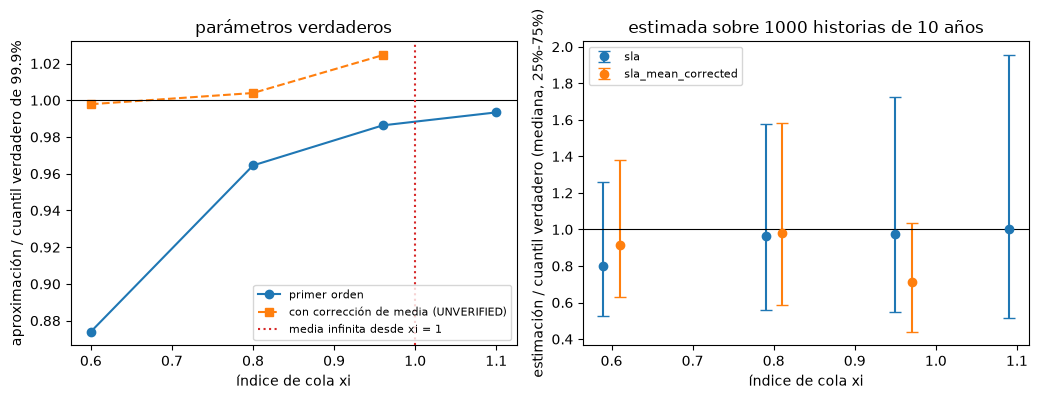

In [9]:
# Dibujar las razones a la verdad: con parámetros verdaderos, y estimadas en 1.000 historias
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
xis = [truth[n]["par"][0] for n in truth]
first_order = [sla.sla_var(t["lam"], "gpd", t["par"], 0.999) / t["q"]["fft"] for t in truth.values()]
corrected = []
for t in truth.values():
    try:
        corrected.append(sla.sla_var_mean_corrected(t["lam"], "gpd", t["par"], 0.999).var / t["q"]["fft"])
    except ValueError:
        corrected.append(np.nan)
left.plot(xis, first_order, "o-", label="primer orden")
left.plot(xis, corrected, "s--", label="con corrección de media (UNVERIFIED)")
left.axhline(1.0, color="black", linewidth=0.8)
left.axvline(1.0, color="tab:red", linestyle=":", label="media infinita desde xi = 1")
left.set_xlabel("índice de cola xi")
left.set_ylabel("aproximación / cuantil verdadero de 99.9%")
left.set_title("parámetros verdaderos")
left.legend(fontsize=8)

for rung, color, shift in (("sla", "tab:blue", -0.01), ("sla_mean_corrected", "tab:orange", 0.01)):
    xs, med, lo, hi = [], [], [], []
    for name in truth:
        block = estimates[(name, rung)]
        if block is None:
            continue
        xs.append(truth[name]["par"][0] + shift)
        med.append(block["ratio_to_truth"]["median"])
        lo.append(block["ratio_to_truth"]["p25"])
        hi.append(block["ratio_to_truth"]["p75"])
    right.errorbar(xs, med, yerr=[np.array(med) - np.array(lo), np.array(hi) - np.array(med)], fmt="o", color=color, capsize=4, label=rung)
right.axhline(1.0, color="black", linewidth=0.8)
right.set_xlabel("índice de cola xi")
right.set_ylabel("estimación / cuantil verdadero (mediana, 25%-75%)")
right.set_title("estimada sobre 1000 historias de 10 años")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **La aproximación con parámetros verdaderos.** La forma de primer orden es 0,874, 0,965, 0,986 y 0,993 del cuantil de 99,9% verdadero para los índices de cola 0,6, 0,8, 0,96 y 1,1: queda bajo la verdad y cierra la brecha cuando la cola se vuelve más pesada, lo que predice un enunciado asintótico para colas pesadas. El recálculo coincide con el valor versionado hasta el redondeo del archivo, y el motor instalado 0.8.1 reproduce lo que calculó el 0.7.0.
- **La forma cerrada y su escalamiento.** `sla_var_poisson_gpd` es igual a `sla_var` hasta el centavo, y duplicar el número esperado de pérdidas multiplica la cantidad desplazada por 1,516, 1,741, 1,945 y 2,144, exactamente $2^{\xi}$. Con un índice de cola menor que 1, el capital crece menos que proporcionalmente a la frecuencia; sobre 1, crece más.
- **La corrección de media.** Sumar $E[N]E[X]$ da 0,998, 1,004 y 1,025 de la verdad para las tres variantes de media finita, a menos de 2,5% de ella; el término agregado es igual a la pérdida anual media verdadera versionada (EUR 4,20 millones, 6,44 millones y 24,26 millones). El motor marca la forma como `UNVERIFIED` en cada resultado, porque la investigación detrás de ella no la verificó contra ninguno de los dos textos primarios, así que es una comparación y no una fórmula validada.
- **La zona de media infinita.** Con índice de cola 1,1 `severity_moment` devuelve infinito, `sla_var_mean_corrected` falla y `es_for_severity` falla antes de calcular nada. Con índice de cola 0,6, donde la media existe, una grilla de Fourier que cubre la cola (masa más allá de ella 5,7e-7) da una pérdida esperada en la cola de 99,9% de EUR 74,5 millones, 2,20 veces el valor en riesgo de EUR 33,8 millones.
- **Donde falla.** Para una lognormal con sigma 1 y Poisson(100), la aproximación es 71,2 frente a un exacto 270,2, una razón de 0,263: es un enunciado sobre colas pesadas. Y con 0,0005 pérdidas al año no está definida para el nivel de 99,9%, y el motor falla.
- **De la fórmula a una estimación.** Estimada sobre historias de 10 años, la mediana de la aproximación sobre la verdad se mantiene cerca de la fórmula (0,80, 0,96, 0,98 y 1,00), pero el rango intercuartil sobre la verdad es 0,73, 1,02, 1,18 y 1,44, tan ancho como la verdad o más, y la proporción de historias que subestiman es 0,63 con índice de cola 0,6 y cerca de la mitad en los otros. La estimación con corrección de media está definida en 988 de 1.000 historias con índice de cola 0,8, en 683 con 0,96 y en ninguna con 1,1, con una mediana de 0,715 de la verdad con 0,96.

Lo que este cuaderno no muestra: cómo un banco elegiría los parámetros que inserta en la fórmula (cuaderno 02), ni cómo el enfoque estándar responde la misma pregunta sin una distribución (cuaderno 05).

## Resumen

- La aproximación de pérdida única lee el cuantil de 99,9% de la pérdida anual como el cuantil de la severidad en $1 - (1 - \alpha)/E[N]$; para colas pesadas queda a menos de 13% de la verdad con índice de cola 0,6 y a menos de 1% con 1,1, con parámetros verdaderos.
- Para un conteo Poisson y una severidad Pareto generalizada es una forma cerrada que escala como $\lambda^{\xi}$.
- La forma con corrección de media es más cercana donde la media existe, pero el motor la marca como no verificada; la media, la corrección y la pérdida esperada en la cola no existen con un índice de cola de 1 o más, y el motor las rechaza.
- La aproximación es un enunciado sobre colas pesadas y necesita más de una pérdida esperada por cada $1 - \alpha$ años.
- Estimada sobre una historia de 10 años, es tan dispersa como la cantidad que estima.

**Qué probar a continuación.** Cambia el nivel a 0,99 y mira cómo se mueve la brecha con la verdad. Sortea una historia como hace el cuaderno 02, ajusta su tasa Poisson y su cola Pareto generalizada y ponlas en `sla_var`; compara el resultado con el rango intercuartil de arriba. Sigue con el cuaderno 05.

## Referencias

- Degen, M. (2010), The calculation of minimum regulatory capital using single-loss approximations, Journal of Operational Risk 5(4), 3-17. https://doi.org/10.21314/JOP.2010.084
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40 (ecuaciones 69 y 70). https://arxiv.org/abs/1008.1108 y https://doi.org/10.21314/JOP.2010.077
- Embrechts, P., Kluppelberg, C. y Mikosch, T. (1997), Modelling Extremal Events for Insurance and Finance, Springer, teorema 1.3.9, y Bocker, K. y Sprittulla, J. (2006), Operational VaR: meaningful means, Risk, tal como los citan Shevchenko (2010) y la documentación del motor de `sla_var_mean_corrected`.